In [59]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 150

os.makedirs("figs", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

In [60]:
df = pd.read_csv(r"C:\Users\huawei\Downloads\company_esg_financial_dataset\company_esg_financial_dataset.csv")
print(f"Shape: {df.shape}")
print("列名:")
for c in df.columns:
    print(f"  {c}")
df.head(3)

Shape: (11000, 16)
列名:
  CompanyID
  CompanyName
  Industry
  Region
  Year
  Revenue
  ProfitMargin
  MarketCap
  GrowthRate
  ESG_Overall
  ESG_Environmental
  ESG_Social
  ESG_Governance
  CarbonEmissions
  WaterUsage
  EnergyConsumption


,CompanyID,CompanyName,Industry,Region,Year,Revenue,ProfitMargin,MarketCap,GrowthRate,ESG_Overall,ESG_Environmental,ESG_Social,ESG_Governance,CarbonEmissions,WaterUsage,EnergyConsumption
0,1,Company_1,Retail,Latin America,2015,459.2,6.0,337.5,NaN,57.0,60.7,33.5,76.8,35577.4,17788.7,71154.7
1,1,Company_1,Retail,Latin America,2016,473.8,4.6,366.6,3.2,56.7,58.9,32.8,78.5,37314.7,18657.4,74629.4
2,1,Company_1,Retail,Latin America,2017,564.9,5.2,313.4,19.2,56.5,57.6,34.0,77.8,45006.4,22503.2,90012.9


In [61]:
# ## 1. Column Standardization & Type Conversion

# %%
# ---- 1a. 重命名列 ----
df = df.rename(columns={
    "CompanyID": "company_id",
    "CompanyName": "company_name",
    "Industry": "industry",
    "Region": "region",
    "Year": "year",
    "Revenue": "revenue",
    "ProfitMargin": "profit_margin",
    "MarketCap": "market_cap",
    "GrowthRate": "growth_rate",
    "ESG_Overall": "esg_overall",
    "ESG_Environmental": "esg_environmental",
    "ESG_Social": "esg_social",
    "ESG_Governance": "esg_governance",
    "CarbonEmissions": "carbon_emissions",
    "WaterUsage": "water_usage",
    "EnergyConsumption": "energy_consumption",
})

# ---- 1b. 数值化 ----
numeric_cols = [
    "esg_overall", "esg_environmental", "esg_social", "esg_governance",
    "revenue", "profit_margin", "market_cap", "growth_rate",
    "carbon_emissions", "water_usage", "energy_consumption", "year"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# ---- 1c. 校验 ----
print("✓ 列名映射完成")
print(f"✓ 数值列类型:\n{df[numeric_cols].dtypes}")
print(f"\n✓ 各列 NaN 数量:\n{df[numeric_cols].isna().sum().to_string()}")
print(f"\n✓ 数据形状: {df.shape}")
print(f"✓ industry 列前5个值: {df['industry'].dropna().unique()[:5]}")

✓ 列名映射完成
✓ 数值列类型:
esg_overall           float64
esg_environmental     float64
esg_social            float64
esg_governance        float64
revenue               float64
profit_margin         float64
market_cap            float64
growth_rate           float64
carbon_emissions      float64
water_usage           float64
energy_consumption    float64
year                    int64
dtype: object

✓ 各列 NaN 数量:
esg_overall              0
esg_environmental        0
esg_social               0
esg_governance           0
revenue                  0
profit_margin            0
market_cap               0
growth_rate           1000
carbon_emissions         0
water_usage              0
energy_consumption       0
year                     0

✓ 数据形状: (11000, 16)
✓ industry 列前5个值: ['Retail' 'Transportation' 'Technology' 'Finance' 'Healthcare']


In [62]:
print(df.isna().sum())
print(f"\n数据类型:\n{df.dtypes}")

company_id               0
company_name             0
industry                 0
region                   0
year                     0
revenue                  0
profit_margin            0
market_cap               0
growth_rate           1000
esg_overall              0
esg_environmental        0
esg_social               0
esg_governance           0
carbon_emissions         0
water_usage              0
energy_consumption       0
dtype: int64

数据类型:
company_id              int64
company_name           object
industry               object
region                 object
year                    int64
revenue               float64
profit_margin         float64
market_cap            float64
growth_rate           float64
esg_overall           float64
esg_environmental     float64
esg_social            float64
esg_governance        float64
carbon_emissions      float64
water_usage           float64
energy_consumption    float64
dtype: object


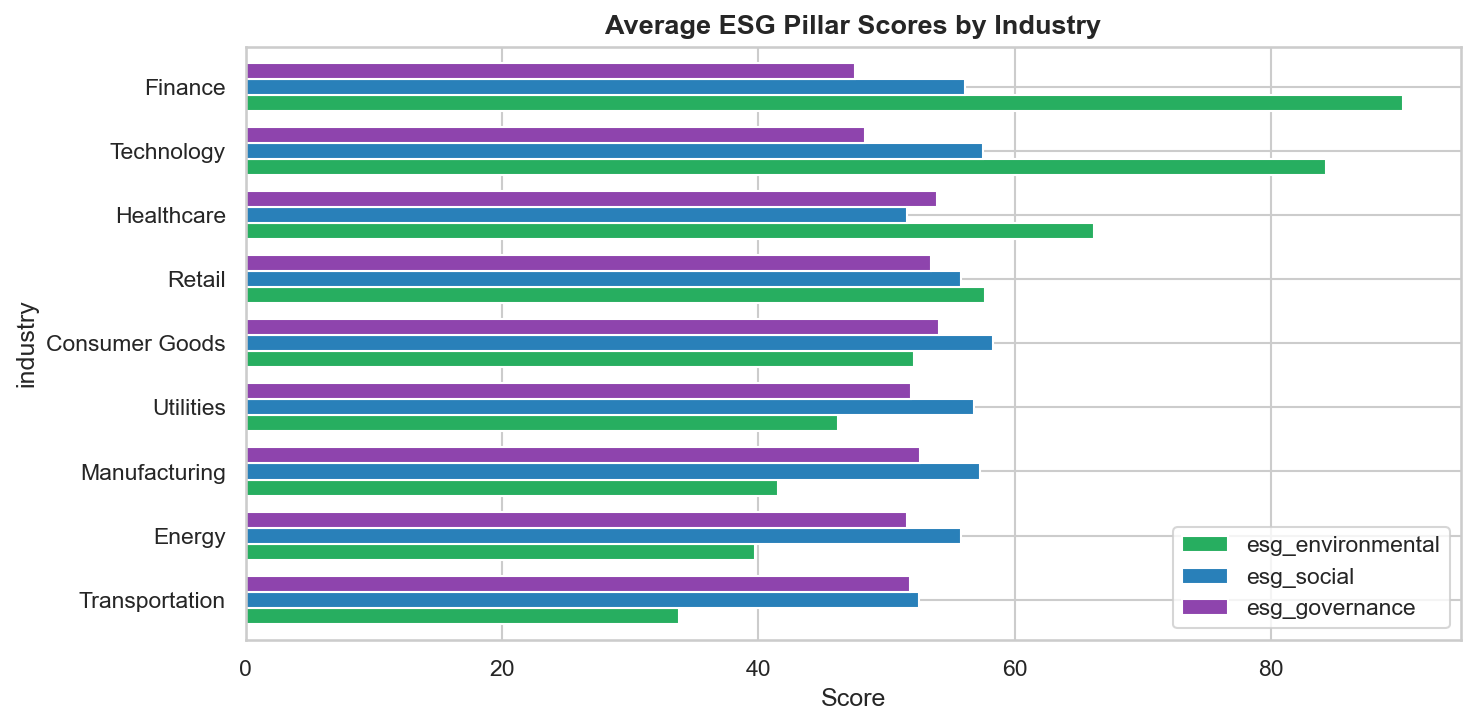

行业 ESG 均值:
                esg_environmental  esg_social  esg_governance
industry                                                     
Transportation               33.8        52.5            51.8
Energy                       39.7        55.8            51.6
Manufacturing                41.5        57.3            52.6
Utilities                    46.2        56.8            51.9
Consumer Goods               52.1        58.3            54.1
Retail                       57.7        55.8            53.5
Healthcare                   66.2        51.6            53.9
Technology                   84.3        57.5            48.3
Finance                      90.3        56.1            47.5


In [63]:
ind = (df.groupby("industry")[["esg_environmental","esg_social","esg_governance"]]
         .mean().round(1)
         .sort_values("esg_environmental"))

fig, ax = plt.subplots(figsize=(10, 5))
ind.plot(kind="barh", ax=ax,
         color=["#27ae60","#2980b9","#8e44ad"], width=0.75)
ax.set_title("Average ESG Pillar Scores by Industry", fontsize=13, fontweight="bold")
ax.set_xlabel("Score")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figs/industry_esg.png", bbox_inches="tight", dpi=150)
plt.show()

print("行业 ESG 均值:")
print(ind)

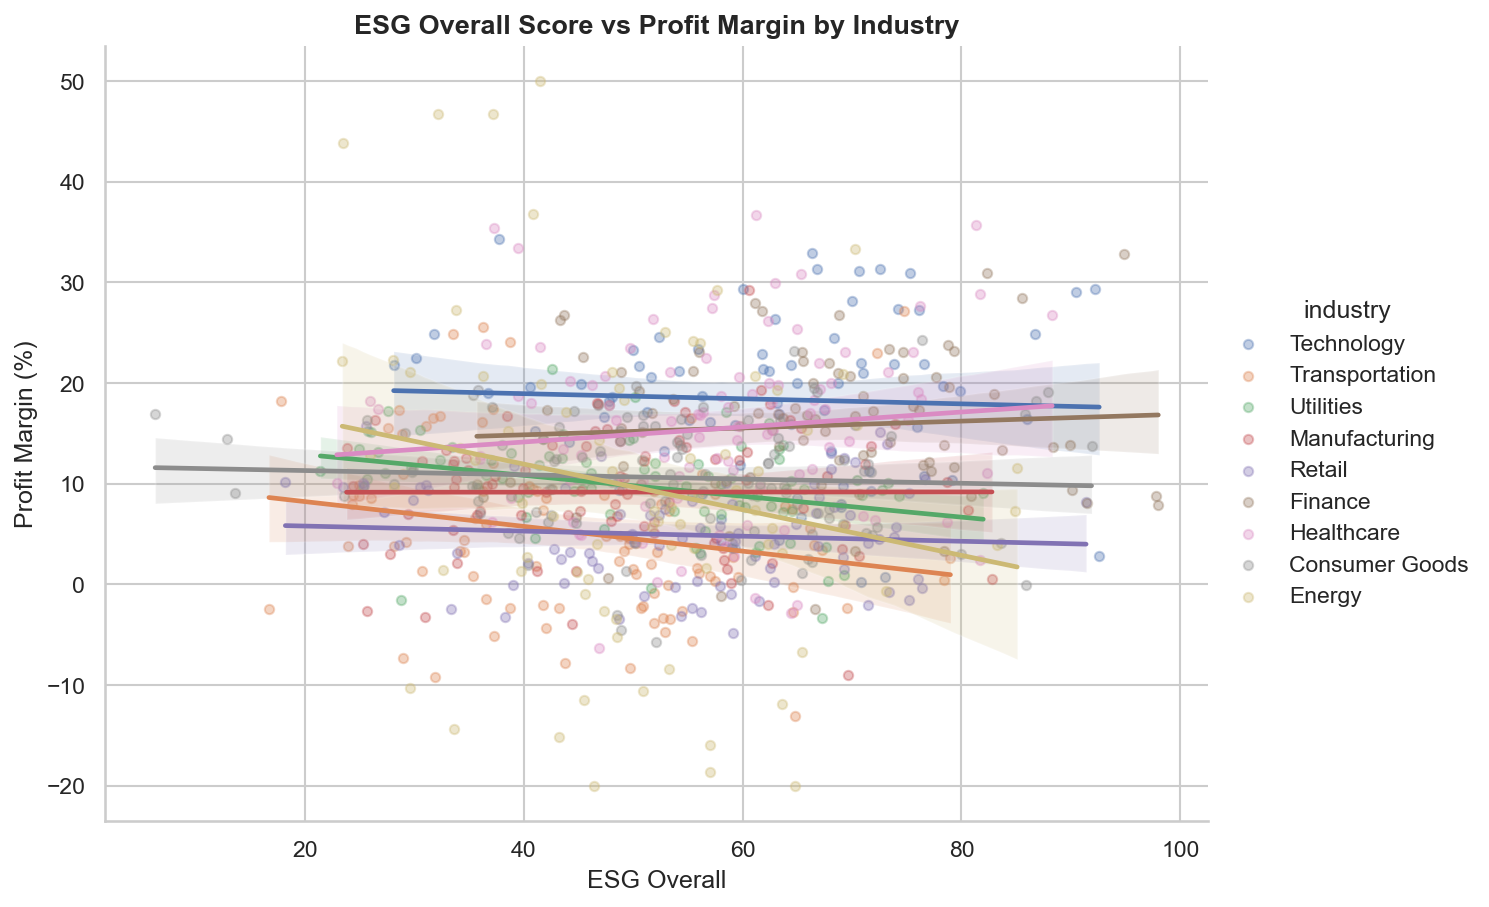

Pearson r = 0.088, p = 2.31e-20


In [64]:
sample = df.sample(min(800, len(df)), random_state=42)

sns.lmplot(data=sample, x="esg_overall", y="profit_margin",
           hue="industry", height=6, aspect=1.4,
           scatter_kws={"alpha": 0.35, "s": 20})

plt.title("ESG Overall Score vs Profit Margin by Industry", fontsize=13, fontweight="bold")
plt.xlabel("ESG Overall")
plt.ylabel("Profit Margin (%)")
plt.savefig("figs/esg_profit.png", bbox_inches="tight", dpi=150)
plt.show()

r, p = stats.pearsonr(df["esg_overall"], df["profit_margin"])
print(f"Pearson r = {r:.3f}, p = {p:.2e}")

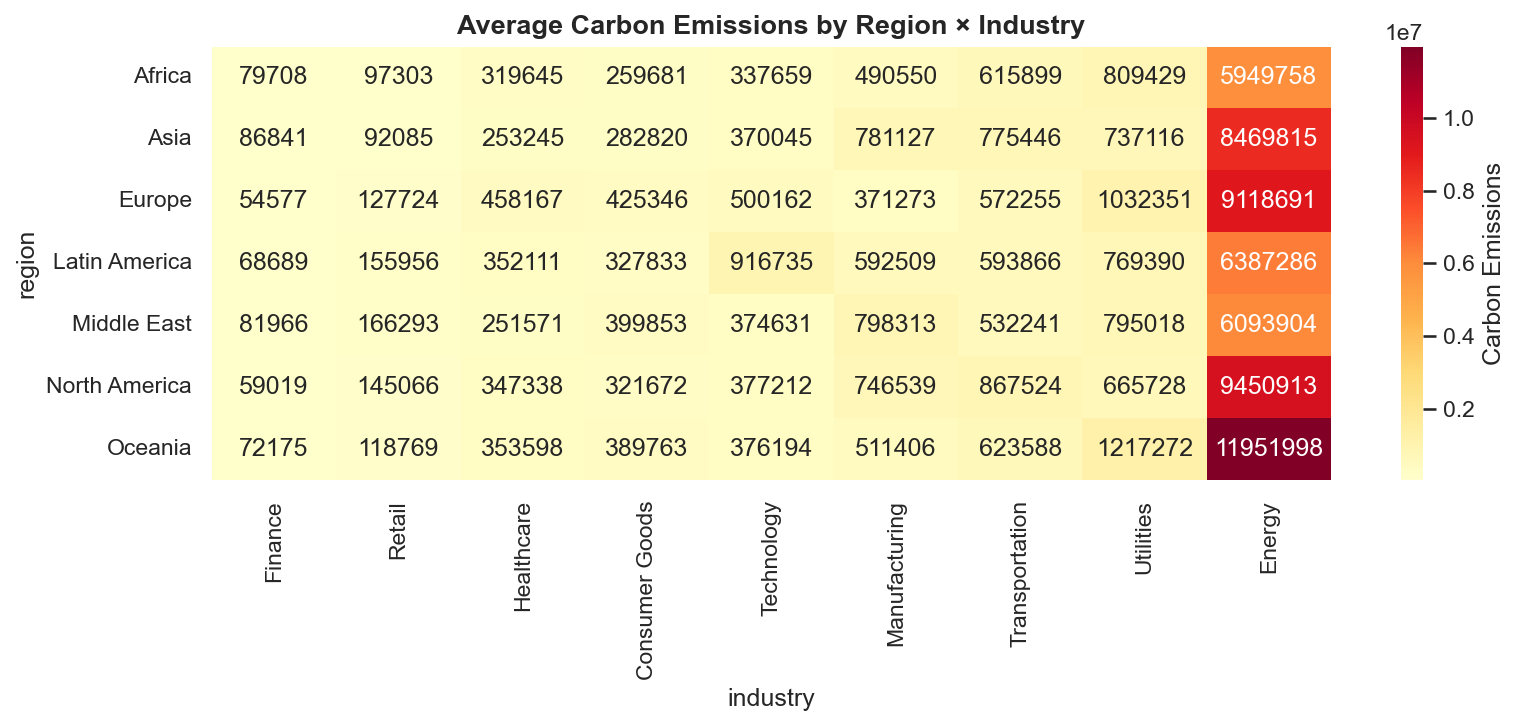

In [65]:
pivot = df.pivot_table(index="region", columns="industry",
                       values="carbon_emissions", aggfunc="mean").round(0)

# 按均值排序
col_order = pivot.mean().sort_values().index
pivot = pivot[col_order]

plt.figure(figsize=(11, 5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlOrRd",
            cbar_kws={"label": "Carbon Emissions"})
plt.title("Average Carbon Emissions by Region × Industry", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("figs/region_carbon.png", bbox_inches="tight", dpi=150)
plt.show()

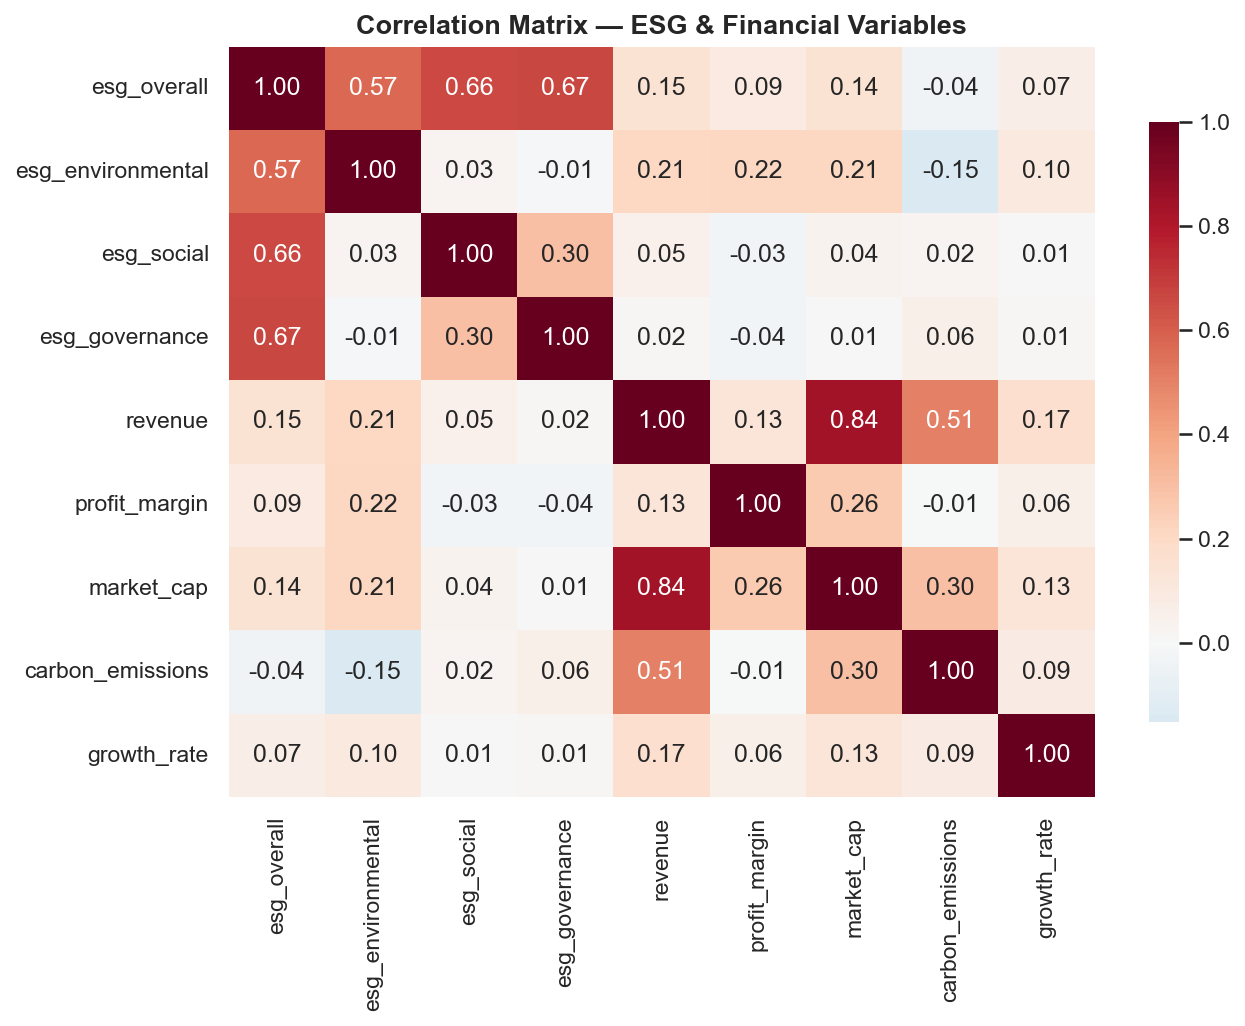

In [66]:
cols = ["esg_overall","esg_environmental","esg_social","esg_governance",
        "revenue","profit_margin","market_cap","carbon_emissions","growth_rate"]

corr = df[cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            cbar_kws={"shrink": 0.8})
plt.title("Correlation Matrix — ESG & Financial Variables", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("figs/corr.png", bbox_inches="tight", dpi=150)
plt.show()

In [67]:
summary = pd.DataFrame({
    "metric": [
        "n_companies", "n_industries", "n_regions", "year_range",
        "pearson_r_esg_profit", "p_value",
        "top_esg_industry", "bottom_esg_industry",
        "avg_carbon_all", "avg_esg_all"
    ],
    "value": [
        df["company_id"].nunique(), df["industry"].nunique(), df["region"].nunique(),
        f"{df['year'].min()}–{df['year'].max()}",
        f"{r:.3f}", f"{p:.2e}",
        ind.index[-1], ind.index[0],
        f"{df['carbon_emissions'].mean():.0f}",
        f"{df['esg_overall'].mean():.1f}"
    ]
})
summary.to_csv("outputs/summary.csv", index=False)
print(summary)

✓ 摘要已导出 → outputs/summary.csv
                 metric           value
0           n_companies            1000
1          n_industries               9
2             n_regions               7
3            year_range       2015–2025
4  pearson_r_esg_profit           0.088
5               p_value        2.31e-20
6      top_esg_industry         Finance
7   bottom_esg_industry  Transportation
8        avg_carbon_all         1271462
9           avg_esg_all            54.6


可用行数: 11000


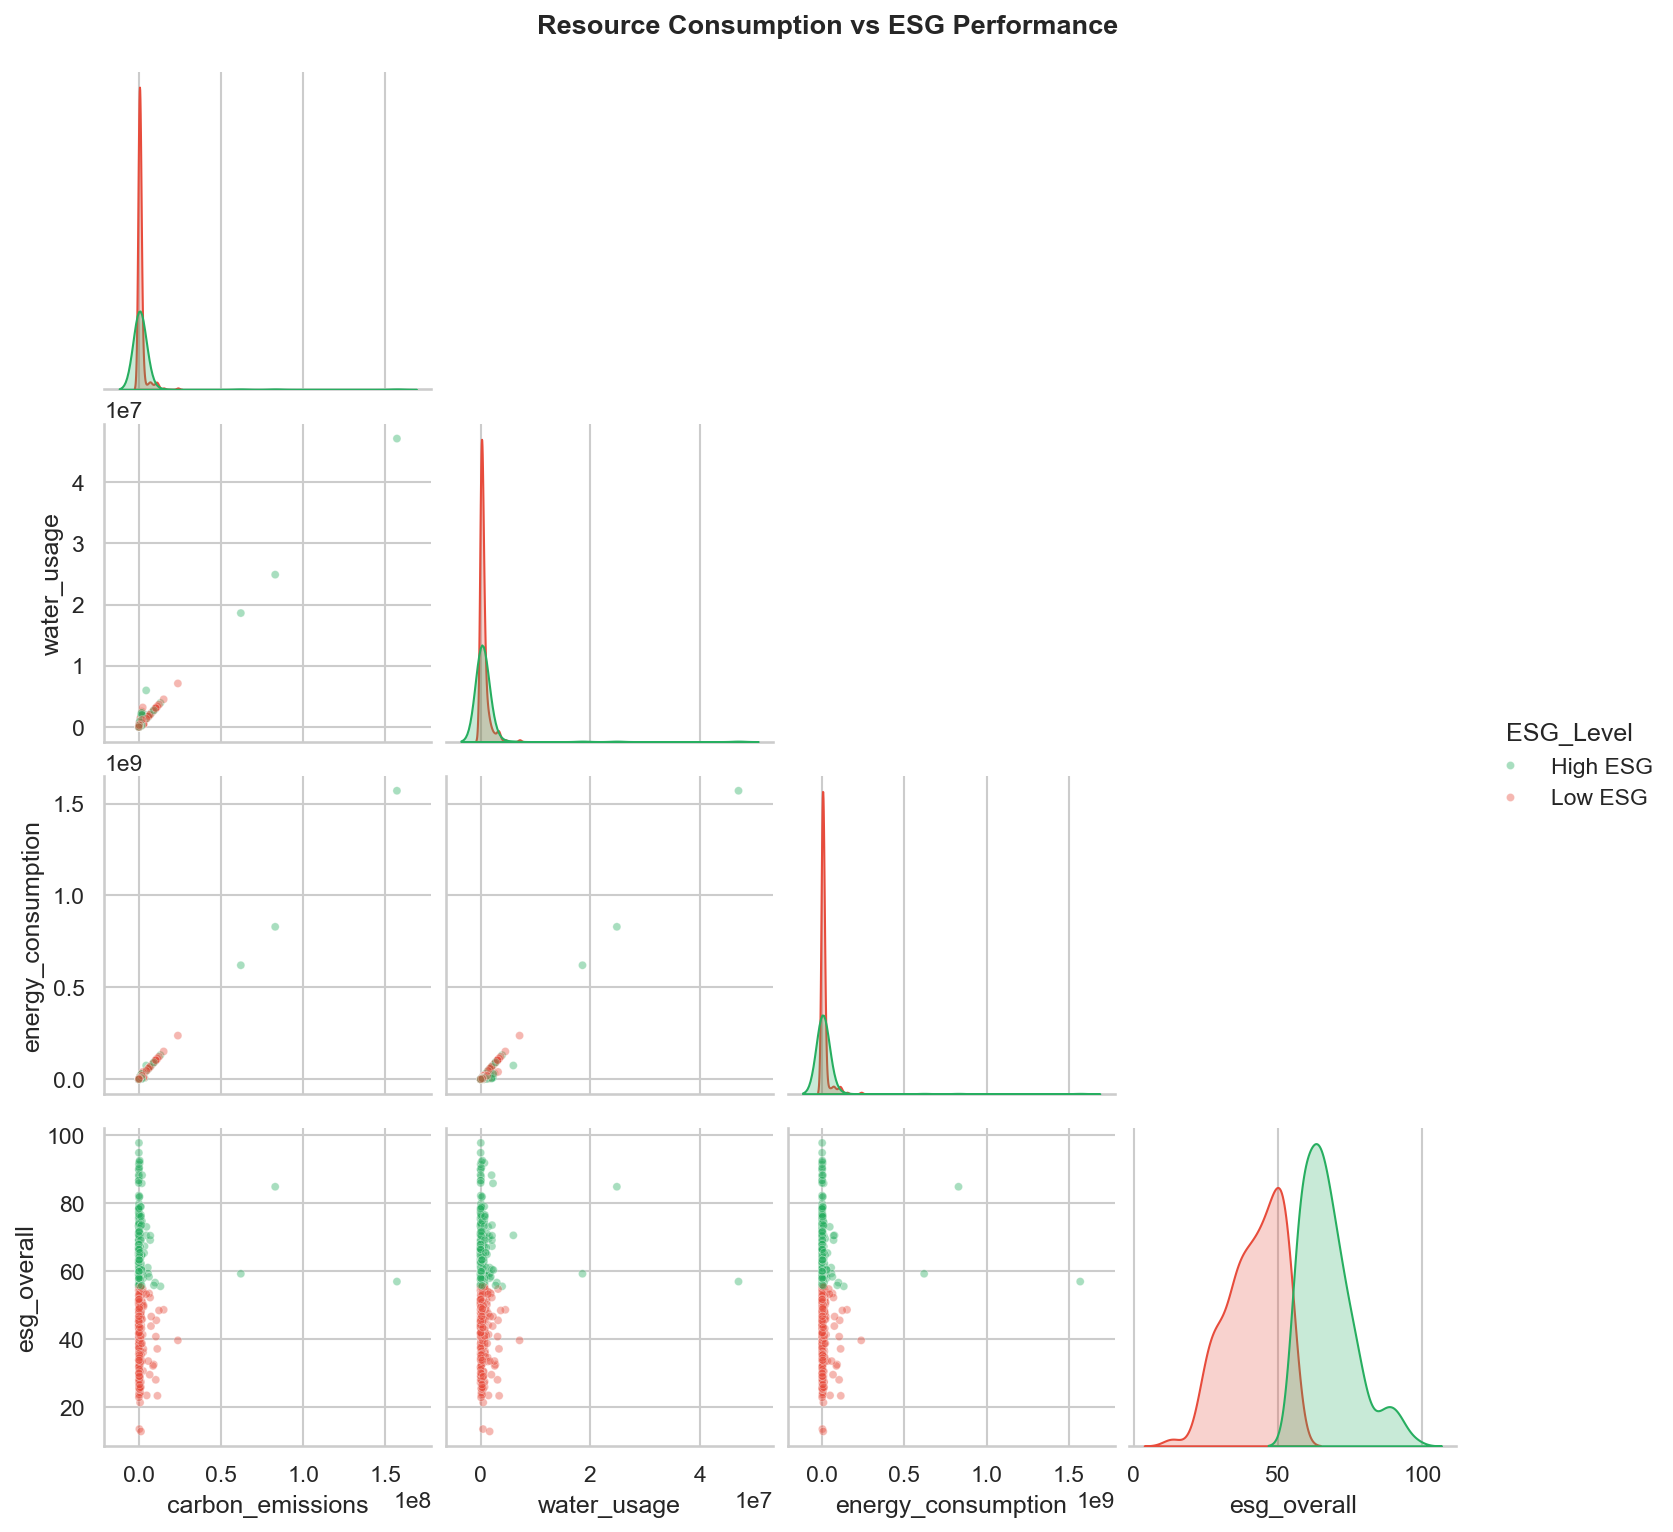

✓ 图已保存 → figs/resource_esg.png


In [68]:
# 资源消耗散点矩阵
sub = (df[["carbon_emissions","water_usage","energy_consumption","esg_overall"]]
       .dropna())

print(f"可用行数: {len(sub)}")

if len(sub) >= 10:
    sub = sub.sample(min(500, len(sub)), random_state=42)
    
    median_val = sub["esg_overall"].median()
    sub["ESG_Level"] = np.where(sub["esg_overall"] > median_val, "High ESG", "Low ESG")
    
    g = sns.pairplot(sub, hue="ESG_Level", corner=True, diag_kind="kde",
                     plot_kws={"alpha": 0.4, "s": 15},
                     palette={"High ESG": "#27ae60", "Low ESG": "#e74c3c"})
    g.fig.suptitle("Resource Consumption vs ESG Performance", y=1.02, fontsize=13, fontweight="bold")
    plt.savefig("figs/resource_esg.png", bbox_inches="tight", dpi=150)
    plt.show()